===== 1. Wczytanie danych =====

Kształt zbioru: (1159, 4)

       polish          dari          pos   sd
0  akceptować  kabul kardan         verb  ---
1      akurat         fakat       adverb  ---
2    akwedukt        tarnał         noun    2
3        albo            ja  conjunction  ---
4   albo-albo         ja-ja  conjunction  ---

Braki w kolumnach:
polish    0
dari      1
pos       0
sd        0
dtype: int64

===== 2. Eksploracyjna analiza danych =====

Rozkład części mowy:
pos
noun            639
verb            224
adjective       143
adverb           79
preposition      24
pronoun          22
conjunction      18
interjection      4
particle          3
phrase            2
determiner        1
Name: count, dtype: int64


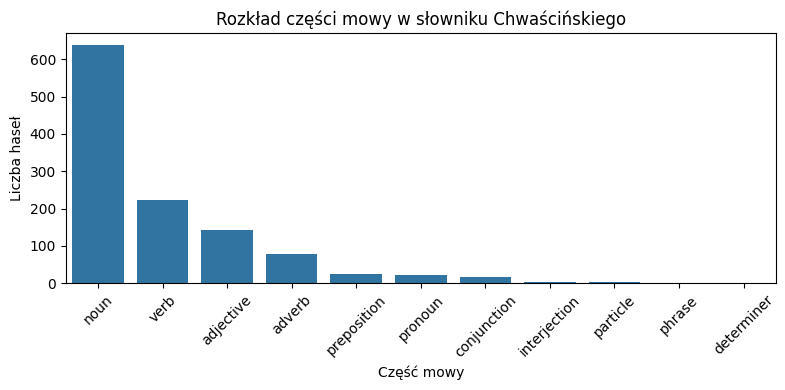

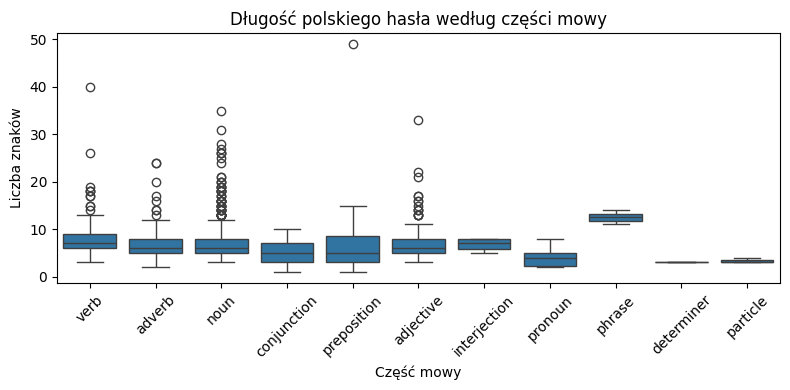


Długość hasła rzeczownikowego mocno zachodzi na pozostałe klasy,
więc sama długość nie wystarcza do rozpoznania rzeczownika.

===== 3. Inżynieria cech =====

Cechy są kontrastowe: końcówki -ć, ' się' i -dan/-tan oznaczają czasownik,
a -y/-i przymiotnik, więc ich brak zwiększa szansę, że hasło to rzeczownik.
Końcówki -dan i -tan to jeden sufiks werbalny (alternacja d~t),
dlatego łączę je w jedną cechę ends_verbal_inf.
Kolumny 'pos' i 'sd' nie wchodzą do cech: 'pos' to etykieta, a 'sd' jest
wypełnione tylko dla rzeczowników, więc wprost zdradzałoby klasę.
Udział klasy 'rzeczownik': 0.551
Liczba cech: 10

Przypadki graniczne w danych (źródło systematycznych pomyłek):
-- rzeczowniki z dari na -dan/-tan (wyglądają na czasownik): 8
-- czasowniki na -c, a nie -ć (welarne, pomijane przez ends_c_acute): 2
-- rzeczowniki na -y/-i (odmiana przymiotnikowa, mylone z przymiotnikiem): 18
-- przysłówki na -o (dzielą tę końcówkę z rzeczownikami nijakimi): 18

===== 4. Podział na zbiory =====

Zbiór tr

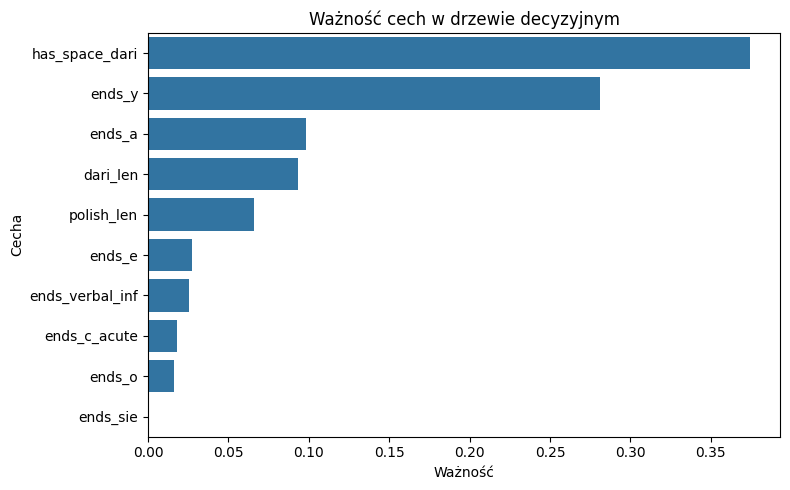


===== 7. Algorytm kNN =====

kNN liczy odległości między hasłami, dlatego cechy najpierw standaryzuję --
inaczej cechy o większych wartościach (długości) zdominowałyby binarne (0--1).

Wpływ liczby sąsiadów k na dokładność:
k  | train | test
 1 | 0.947 | 0.819
 3 | 0.901 | 0.810
 5 | 0.887 | 0.841
 7 | 0.883 | 0.858
15 | 0.872 | 0.849
25 | 0.861 | 0.866

Przy k=1 klasyfikator jest przeuczony (train ~0.95). Większe k daje
stabilniejszy wynik. Wybieram k=5.

kNN (k=5, cechy standaryzowane):
Dokładność (test): 0.841
Walidacja krzyżowa (cv=3), średnia: 0.859

===== 8. Macierze pomyłek i metryki =====

Macierz pomyłek -- drzewo decyzyjne:
[[91 14]
 [29 98]]


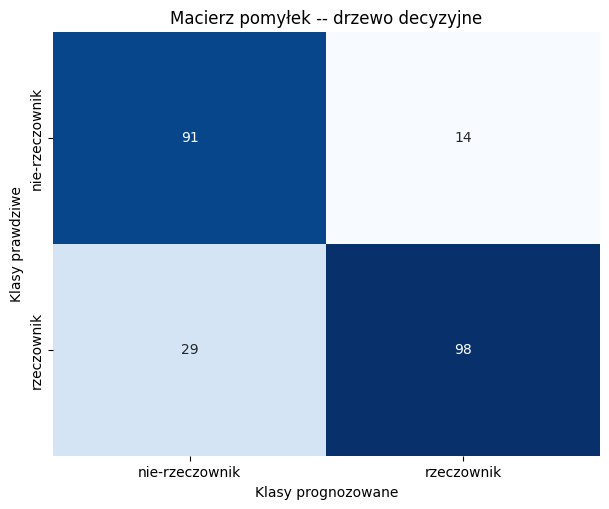


Macierz pomyłek -- kNN:
[[ 87  18]
 [ 19 108]]


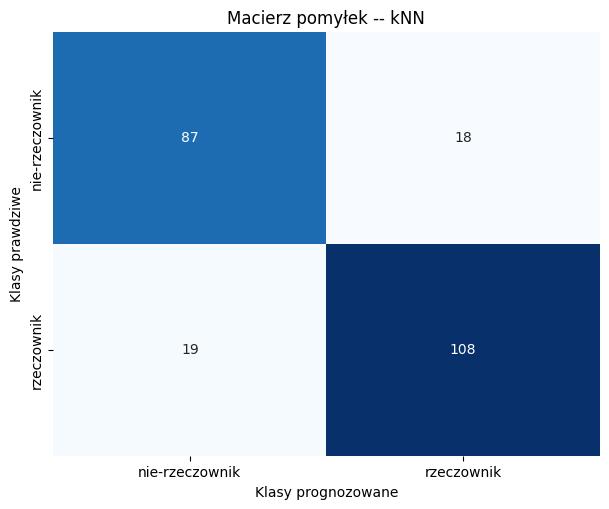


Przy niezbalansowanych klasach sama dokładność bywa myląca, dlatego
oceniam też precyzję i pełność dla klasy pozytywnej ('rzeczownik').
Metryki dla klasy 'rzeczownik' (precyzja / pełność / F1):
drzewo: 0.875 0.772 0.82
kNN:    0.857 0.85 0.854

===== 9. Wnioski =====

Wyniki
------
Klasyfikator bazowy osiąga ok. 55% (zawsze 'rzeczownik'). Drzewo (~82%)
i kNN (~84%) przekraczają ten próg o blisko 30 punktów procentowych,
a walidacja krzyżowa (~86%) potwierdza, że wynik nie zależy od jednego podziału.

Interpretacja cech
------------------
Najważniejsze cechy to has_space_dari i ends_y, czyli sygnały kontrastowe,
a nie pozytywny marker rzeczownika (taki nie istnieje). Model uczy się wykluczać
hasła wyglądające na czasownik lub przymiotnik, więc ważność cech trzeba
czytać w kontekście danych, a nie dosłownie.

Ograniczenia
------------
-- Rzeczownik nie ma jednego markera morfologicznego, co ogranicza pułap
   dokładności przy tak prostych cechach (~82--84%).
-- Cechy zaprojektowano ręcz

In [1]:
"""
Mini-projekt zaliczeniowy

Tytuł:     Rozpoznawanie rzeczowników w słowniku Bolesława Chwaścińskiego
Autor:     Wojciech Fotek
Przedmiot: Wprowadzenie do uczenia maszynowego i analizy danych dla studentów kierunków nieinformatycznych 
           (ZOOPLS.D200000.18111.26, dr inż. Joanna Świebocka-Więk)

Cel projektu
------------
Zbudowanie modelu uczenia nadzorowanego, który na podstawie cech leksykalnych
i ortograficznych hasła rozpoznaje, czy dane hasło jest rzeczownikiem.

Rzeczowniki stanowią ok. 55% haseł i nie mają jednego
silnego markera morfologicznego. Model musi więc opierać się na cechach
kontrastowych: rozpoznaje rzeczownik raczej przez wykluczenie.
Dlatego skok nad klasyfikatorem bazowym jest umiarkowany,
a sama dokładność nie wystarcza do oceny.

Dane pochodzą z bazy leksykalnej przygotowanej w ramach mojej pracy licencjackiej
pt. "An Analysis of Bolesław Chwaściński's Kaboli Dictionary and Grammatical Sketch"
napisanej pod kierunkiem dr. Mateusza M. Kłagisza w Instytucie Orientalistyki UJ.
Baza liczy 1159 wyrównanych haseł z trzech rękopisów:
MS 1 (polsko-dari, 1143 hasła), MS 2 (dari-polski, 995 haseł)
oraz RB (polsko-dari, 1067 haseł).

Opis kolumn
-----------
polish     polskie hasło bazowe, głównie z MS 1
dari       ekwiwalent hasła bazowego w dari, głównie z MS 1 (zapis w transkrypcji, często bez znaków diakrytycznych)
pos        część mowy
sd         kod domeny semantycznej (1--11) wg klasyfikacji z mojej pracy licencjackiej;
           '---' dla haseł niesklasyfikowanych
"""

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score



print("===== 1. Wczytanie danych =====")
print()

data = pd.read_csv("data.csv")

print("Kształt zbioru:", data.shape)
print()
print(data.head())
print()
print("Braki w kolumnach:")
print(data.isnull().sum())



print()
print("===== 2. Eksploracyjna analiza danych =====")
print()

print("Rozkład części mowy:")
print(data["pos"].value_counts())

plt.figure(figsize=(8, 4))
sns.barplot(x=data["pos"].value_counts().index,
            y=data["pos"].value_counts().values)
plt.title("Rozkład części mowy w słowniku Chwaścińskiego")
plt.xlabel("Część mowy")
plt.ylabel("Liczba haseł")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

data["polish_len"] = data["polish"].str.len()

plt.figure(figsize=(8, 4))
sns.boxplot(data=data, x="pos", y="polish_len")
plt.title("Długość polskiego hasła według części mowy")
plt.xlabel("Część mowy")
plt.ylabel("Liczba znaków")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print()
print("Długość hasła rzeczownikowego mocno zachodzi na pozostałe klasy,")
print("więc sama długość nie wystarcza do rozpoznania rzeczownika.")



print()
print("===== 3. Inżynieria cech =====")

data["is_noun"] = (data["pos"] == "noun").astype(int)

polish = data["polish"]
dari = data["dari"].fillna("")

data["dari_len"] = dari.str.len()
data["has_space_dari"] = (dari.str.find(" ") >= 0).astype(int)
data["ends_verbal_inf"] = ((dari.str[-3:] == "dan") | (dari.str[-3:] == "tan")).astype(int)
data["ends_sie"] = (polish.str[-4:] == " się").astype(int)
data["ends_c_acute"] = (polish.str[-1] == "ć").astype(int)
data["ends_y"] = ((polish.str[-1] == "y") | (polish.str[-1] == "i")).astype(int)
data["ends_a"] = (polish.str[-1] == "a").astype(int)
data["ends_e"] = (polish.str[-1] == "e").astype(int)
data["ends_o"] = (polish.str[-1] == "o").astype(int)

feature_cols = [
    "polish_len", "dari_len", "has_space_dari",
    "ends_verbal_inf", "ends_sie", "ends_c_acute",
    "ends_y", "ends_a", "ends_e", "ends_o",
]

X = data[feature_cols]
y = data["is_noun"]

print()
print("Cechy są kontrastowe: końcówki -ć, ' się' i -dan/-tan oznaczają czasownik,")
print("a -y/-i przymiotnik, więc ich brak zwiększa szansę, że hasło to rzeczownik.")
print("Końcówki -dan i -tan to jeden sufiks werbalny (alternacja d~t),")
print("dlatego łączę je w jedną cechę ends_verbal_inf.")
print("Kolumny 'pos' i 'sd' nie wchodzą do cech: 'pos' to etykieta, a 'sd' jest")
print("wypełnione tylko dla rzeczowników, więc wprost zdradzałoby klasę.")
print("Udział klasy 'rzeczownik':", round(y.mean(), 3))
print("Liczba cech:", X.shape[1])

print()
print("Przypadki graniczne w danych (źródło systematycznych pomyłek):")
n_dan = ((data["pos"] == "noun") & (data["ends_verbal_inf"] == 1)).sum()
print("-- rzeczowniki z dari na -dan/-tan (wyglądają na czasownik):", n_dan)
n_velar = ((data["pos"] == "verb") & (polish.str[-1] == "c")).sum()
print("-- czasowniki na -c, a nie -ć (welarne, pomijane przez ends_c_acute):", n_velar)
n_adjn = ((data["pos"] == "noun") & (data["ends_y"] == 1)).sum()
print("-- rzeczowniki na -y/-i (odmiana przymiotnikowa, mylone z przymiotnikiem):", n_adjn)
n_advo = ((data["pos"] == "adverb") & (data["ends_o"] == 1)).sum()
print("-- przysłówki na -o (dzielą tę końcówkę z rzeczownikami nijakimi):", n_advo)



print()
print("===== 4. Podział na zbiory =====")
print()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Zbiór treningowy:", X_train.shape[0], "haseł")
print("Zbiór testowy:   ", X_test.shape[0], "haseł")



print()
print("===== 5. Klasyfikator bazowy =====")
print()

dummy_clf = DummyClassifier()
dummy_clf.fit(X_train, y_train)

print("Czy przypisuje każde hasło do klasy 'rzeczownik'?", all(dummy_clf.predict(X_train)))
print("Dokładność (test):", round(dummy_clf.score(X_test, y_test), 3))
print()
print("Klasyfikator bazowy osiąga tylko ok. 55%, czyli tyle, ile wynosi udział klasy większościowej.")
print("Każdy sensowny model musi ten próg wyraźnie przekroczyć.")



print()
print("===== 6. Drzewo decyzyjne =====")
print()

print("Wpływ głębokości drzewa na dokładność:")
print("max_depth | train | test")
for depth in [1, 2, 3, 5, 8, 12, 20, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    label = str(depth) if depth is not None else "brak"
    print(f"{label:>9} | {model.score(X_train, y_train):.3f} | {model.score(X_test, y_test):.3f}")

print()
print("Płytkie drzewo (max_depth=1) jest niedouczone (~0.72). Przy bardzo głębokim")
print("drzewie dokładność treningowa rośnie do ~0.95, ale testowa spada (~0.80) --")
print("to przeuczenie. Wybieram umiarkowane max_depth=8.")

tree = DecisionTreeClassifier(max_depth=8, random_state=42)
tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

print()
print("Drzewo (max_depth=8):")
print("Dokładność (test):", round(tree.score(X_test, y_test), 3))
cv_tree = cross_val_score(tree, X_train, y_train, cv=3, scoring="accuracy")
print("Walidacja krzyżowa (cv=3), średnia:", round(cv_tree.mean(), 3))

importance_df = pd.DataFrame({
    "feature": feature_cols,
    "importance": tree.feature_importances_
}).sort_values(by="importance", ascending=False)

print()
print("Ważność cech:")
print(importance_df.to_string(index=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x="importance", y="feature")
plt.title("Ważność cech w drzewie decyzyjnym")
plt.xlabel("Ważność")
plt.ylabel("Cecha")
plt.tight_layout()
plt.show()



print()
print("===== 7. Algorytm kNN =====")
print()

print("kNN liczy odległości między hasłami, dlatego cechy najpierw standaryzuję --")
print("inaczej cechy o większych wartościach (długości) zdominowałyby binarne (0--1).")
print()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Wpływ liczby sąsiadów k na dokładność:")
print("k  | train | test")
for k in [1, 3, 5, 7, 15, 25]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    print(f"{k:>2} | {model.score(X_train_scaled, y_train):.3f} | {model.score(X_test_scaled, y_test):.3f}")

print()
print("Przy k=1 klasyfikator jest przeuczony (train ~0.95). Większe k daje")
print("stabilniejszy wynik. Wybieram k=5.")

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)

print()
print("kNN (k=5, cechy standaryzowane):")
print("Dokładność (test):", round(knn.score(X_test_scaled, y_test), 3))
cv_knn = cross_val_score(knn, X_train_scaled, y_train, cv=3, scoring="accuracy")
print("Walidacja krzyżowa (cv=3), średnia:", round(cv_knn.mean(), 3))



print()
print("===== 8. Macierze pomyłek i metryki =====")

labels = ["nie-rzeczownik", "rzeczownik"]

for name, y_pred in [("drzewo decyzyjne", y_pred_tree), ("kNN", y_pred_knn)]:
    cm = confusion_matrix(y_test, y_pred)
    print()
    print(f"Macierz pomyłek -- {name}:")
    print(cm)
    cm_df = pd.DataFrame(cm, index=labels, columns=labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_df, annot=True, fmt="d", cbar=None, cmap="Blues")
    plt.title(f"Macierz pomyłek -- {name}")
    plt.tight_layout()
    plt.ylabel("Klasy prawdziwe")
    plt.xlabel("Klasy prognozowane")
    plt.show()

print()
print("Przy niezbalansowanych klasach sama dokładność bywa myląca, dlatego")
print("oceniam też precyzję i pełność dla klasy pozytywnej ('rzeczownik').")
print("Metryki dla klasy 'rzeczownik' (precyzja / pełność / F1):")
print("drzewo:", round(precision_score(y_test, y_pred_tree), 3),
      round(recall_score(y_test, y_pred_tree), 3),
      round(f1_score(y_test, y_pred_tree), 3))
print("kNN:   ", round(precision_score(y_test, y_pred_knn), 3),
      round(recall_score(y_test, y_pred_knn), 3),
      round(f1_score(y_test, y_pred_knn), 3))



print()
print("===== 9. Wnioski =====")
print()
print("Wyniki")
print("------")
print("Klasyfikator bazowy osiąga ok. 55% (zawsze 'rzeczownik'). Drzewo (~82%)")
print("i kNN (~84%) przekraczają ten próg o blisko 30 punktów procentowych,")
print("a walidacja krzyżowa (~86%) potwierdza, że wynik nie zależy od jednego podziału.")
print()
print("Interpretacja cech")
print("------------------")
print("Najważniejsze cechy to has_space_dari i ends_y, czyli sygnały kontrastowe,")
print("a nie pozytywny marker rzeczownika (taki nie istnieje). Model uczy się wykluczać")
print("hasła wyglądające na czasownik lub przymiotnik, więc ważność cech trzeba")
print("czytać w kontekście danych, a nie dosłownie.")
print()
print("Ograniczenia")
print("------------")
print("-- Rzeczownik nie ma jednego markera morfologicznego, co ogranicza pułap")
print("   dokładności przy tak prostych cechach (~82--84%).")
print("-- Cechy zaprojektowano ręcznie i są specyficzne dla pary polski--dari.")
print("-- Cechy kontrastowe mają systematyczne luki (zliczone w sekcji 3): czasowniki")
print("   welarne na -c, rzeczowniki o odmianie przymiotnikowej na -y/-i")
print("   oraz rzeczowniki z końcówką -dan/-tan są mylone przez model.")